# 09 — Goals prediction: Poisson expected goals, Over/Under and BTTS

**Question:** can we forecast *how many goals* a Serie A match will have, well enough to give
useful Over/Under and Both Teams To Score (BTTS) probabilities? The app's goals section
(commit 14) only shows historical frequencies. This notebook builds and backtests an actual
forecast, and decides whether it is good enough to show in the app.

**Method in one paragraph:** each fixture gets two expected-goals rates, `lambda_home` and
`lambda_away`. Assuming the two goal counts are independent Poisson variables, every Over/Under,
BTTS, exact-score and 1X2 probability follows exactly from those two numbers
(`src/goals_model.py`). Three ways of producing the rates are compared on the same fixtures with
the walk-forward scheme of the 1X2 backtest (`src/goals_backtest.py`, seasons 2018-19 to 2024-25):

| Method | Rates come from |
|---|---|
| **League average** | mean home and away goals of the training seasons (the same for every match) |
| **Team attack/defence** | each club's goals scored and conceded over its recent Serie A matches, shrunk toward the league average, with home advantage |
| **Poisson regression** | two L2-regularised Poisson regressions (home goals, away goals) on the existing engineered pre-match features |

In every fold (evaluation season S) the settings are chosen by fitting on seasons up to S-2 and
scoring on S-1; the choice is then refitted on seasons up to S-1 and scored on S. The 2025-26
validation season and the 2026-27 holdout play no part. Bookmaker odds are never a feature; the
market-average Over/Under 2.5 odds already in the raw files are only a yardstick.

**Contents:** 1. Poisson scoring theory · 2. Existing goals distributions · 3. Predicted expected
goals · 4. Historical performance versus baselines · 5. Over/Under probability quality · 6. BTTS
probability quality · 7. Calibration analysis · 8. Statistical uncertainty · 9. Conclusions and
recommendation

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator, PercentFormatter
from scipy.stats import poisson

from src.backtest import BACKTEST_DIR, BACKTEST_SEASONS, load_backtest
from src.config import FIGURES_DIR
from src.evaluate import OUTCOMES, per_match_log_loss
from src.feature_engineering import load_features
from src.goals_backtest import (
    BASELINES, GOALS_DIR, HEADLINE_METRICS, LEAGUE, MARKET, METHODS, MODEL, PRIMARY_METRICS, TEAM,
    bias_table, calibration_table, dispersion_table, event_outcomes, goals_by_band, load_goals_backtest,
    market_comparison, market_coverage, market_over_under, market_predictions, match_losses, metric_label,
    paired_comparisons, pooled_metrics, readiness, reliability_table, run_goals_backtest, save_goals_backtest,
    score_frequency_table, season_metrics, season_sensitivity,
)
from src.goals_model import (
    EVENTS, GOALS_FEATURE_SETS, PoissonGoalsModel, SideChoice, goal_probabilities, most_likely_scores, played,
    score_grid,
)
from src.train import VALIDATION_SEASON, season_name

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

features = load_features()
history = played(features[features["season_start"] < VALIDATION_SEASON])  # 1993-94 .. 2024-25 only

if (GOALS_DIR / "predictions.csv").exists():
    experiment = load_goals_backtest()
    print("Loaded the saved experiment from outputs/goals/ (python -m src.goals_backtest)")
else:
    start = time.time()
    experiment = run_goals_backtest(features, progress=print)
    save_goals_backtest(experiment, odds=market_over_under(seasons=set(BACKTEST_SEASONS)))
    print(f"Experiment finished in {(time.time() - start) / 60:.1f} minutes")

predictions = experiment.predictions
odds = market_over_under(seasons=set(BACKTEST_SEASONS))  # read from the raw files already on disk
assert set(predictions["season"]) == set(BACKTEST_SEASONS)
assert predictions["season"].max() < VALIDATION_SEASON
N_RESAMPLES = 10_000
SEASON_LABELS = {s: season_name(s) for s in BACKTEST_SEASONS}
print(f"{predictions[predictions['method'] == MODEL].shape[0]:,} fixtures x {predictions['method'].nunique()} methods")

Loaded the saved experiment from outputs/goals/ (python -m src.goals_backtest)


2,660 fixtures x 3 methods


In [2]:
# --- Chart style (same as notebooks 01-08) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE_LINE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#a3a29b"
COLORS = {MODEL: "#2a78d6", TEAM: "#eb6834", LEAGUE: NEUTRAL, MARKET: "#1baf7a"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#f2f7fd", "#9cc3ef", "#2a78d6", "#103d73"])
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efeb", "#eb6834"])


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_LINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")


def legend(ax, **kwargs):
    leg = ax.legend(**({"frameon": False, "fontsize": 8, "labelcolor": INK_2} | kwargs))
    return leg

## 1. Poisson scoring theory

A Poisson variable with mean `λ` counts events that happen independently at a steady rate:

```
P(X = k) = exp(-λ) * λ^k / k!        mean = variance = λ
```

Applied to football: the home side scores `H ~ Poisson(λ_home)` goals and the away side
`A ~ Poisson(λ_away)`, **independently of each other**. Everything else follows exactly:

| Quantity | Formula |
|---|---|
| Total goals | `T = H + A ~ Poisson(λ_home + λ_away)` (a sum of independent Poissons is Poisson) |
| Under x.5 | `P(T <= x)`: the Poisson CDF of `λ_total` at `x` |
| Over x.5 | `1 - P(Under x.5)` |
| BTTS Yes | `P(H >= 1) * P(A >= 1) = (1 - exp(-λ_home)) * (1 - exp(-λ_away))` |
| Exact score h-a | `P(H = h) * P(A = a)` |
| Home win / draw / away win | sums of exact scores with h > a, h = a, h < a |

Complementary pairs are computed as `p` and `1 - p`, so they sum to one exactly. Exact scores and
1X2 use a score grid that grows with the rates until less than `1e-12` of the probability lies
outside it; that leftover ("truncated mass") is reported, and a fixture whose rates are so large
that more than `1e-9` would be lost is refused rather than silently cut. In the backtest the largest
truncated mass is below `1e-12`.

**A worked example.** A home side expected to score 1.55 goals against an away side expected to
score 1.15:

In [3]:
example = goal_probabilities([1.55], [1.15]).iloc[0]
rows = {f"Over {line}": example[f"over_{str(line).replace('.', '_')}"] for line in (0.5, 1.5, 2.5, 3.5)}
rows |= {"BTTS Yes": example["btts_yes"], "Home win": example["H"], "Draw": example["D"], "Away win": example["A"]}
display(pd.Series(rows, name="probability").to_frame().style.format("{:.1%}").set_caption(
    "lambda_home = 1.55, lambda_away = 1.15 (lambda_total = 2.70)"))
display(most_likely_scores(1.55, 1.15, top=5).style.format({"probability": "{:.1%}"}).hide(axis="index")
        .set_caption("The five most likely exact scores"))
print(f"Truncated mass of the adaptive grid: {example['truncated_mass']:.1e}")

,probability
Over 0.5,93.3%
Over 1.5,75.1%
Over 2.5,50.6%
Over 3.5,28.6%
BTTS Yes,53.8%
Home win,46.5%
Draw,25.2%
Away win,28.2%


home_goals,away_goals,probability,score
1,1,12.0%,1-1
1,0,10.4%,1-0
2,1,9.3%,2-1
2,0,8.1%,2-0
0,1,7.7%,0-1


Truncated mass of the adaptive grid: 9.7e-14


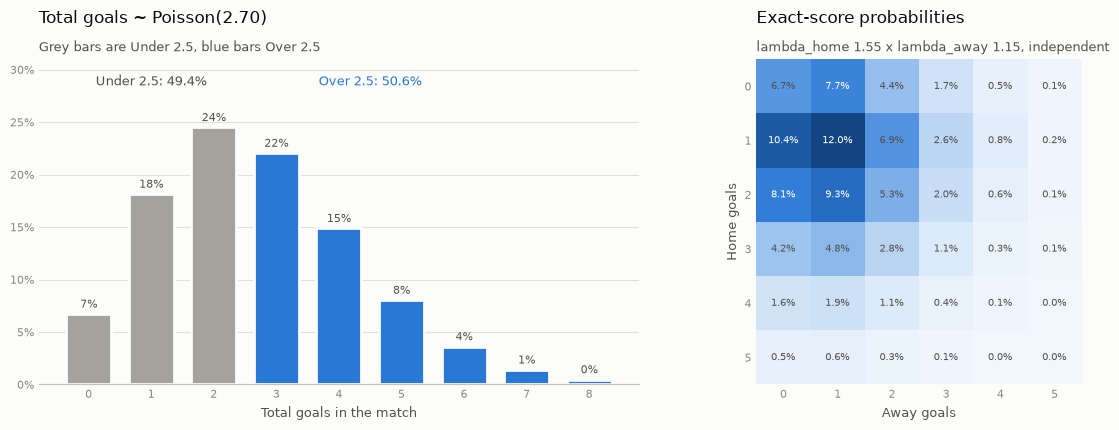

In [4]:
# Figure 45: the total-goals distribution and the score grid of the example
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
fig.patch.set_facecolor(SURFACE)
k = np.arange(0, 9)
pmf = poisson.pmf(k, 2.70)
ax1.bar(k, pmf, width=0.72, color=[NEUTRAL if v <= 2 else COLORS[MODEL] for v in k], edgecolor=SURFACE, linewidth=2)
for x, y in zip(k, pmf):
    ax1.text(x, y + 0.006, f"{y:.0%}", ha="center", fontsize=8, color=INK_2)
ax1.text(1, 0.285, f"Under 2.5: {pmf[:3].sum():.1%}", ha="center", fontsize=9, color=INK_2)
ax1.text(4.5, 0.285, f"Over 2.5: {1 - pmf[:3].sum():.1%}", ha="center", fontsize=9, color=COLORS[MODEL])
style_axes(ax1)
ax1.set_xticks(k)
ax1.set_ylim(0, 0.31)
ax1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax1.set_xlabel("Total goals in the match", fontsize=9, color=INK_2)
set_title(ax1, "Total goals ~ Poisson(2.70)", "Grey bars are Under 2.5, blue bars Over 2.5")

grid = score_grid([1.55], [1.15], max_goals=5).probabilities[0]
ax2.imshow(grid, cmap=BLUES, vmin=0, vmax=grid.max() * 1.05)
for h in range(6):
    for a in range(6):
        ax2.text(a, h, f"{grid[h, a]:.1%}", ha="center", va="center", fontsize=7.5,
                 color="white" if grid[h, a] > 0.07 else INK_2)
ax2.set_xticks(range(6))
ax2.set_yticks(range(6))
ax2.tick_params(colors=MUTED, labelsize=8, length=0)
for side in ax2.spines.values():
    side.set_visible(False)
ax2.set_xlabel("Away goals", fontsize=9, color=INK_2)
ax2.set_ylabel("Home goals", fontsize=9, color=INK_2)
set_title(ax2, "Exact-score probabilities", "lambda_home 1.55 x lambda_away 1.15, independent")
fig.tight_layout()
save_figure(fig, "45_poisson_theory.png")
plt.show()

## 2. Existing goals distributions

Before modelling anything: how well does a Poisson distribution describe Serie A goals at all?
All completed matches from 1993-94 to 2024-25 are used here (descriptive only; 2025-26 and later
are left out like everywhere else in this notebook). Each panel compares the observed frequencies
with a Poisson distribution that has the same mean.

In [5]:
goals = {"Home goals": history["home_goals"].astype(int), "Away goals": history["away_goals"].astype(int),
         "Total goals": (history["home_goals"] + history["away_goals"]).astype(int)}
summary = {}
for name, values in goals.items():
    mean, var = values.mean(), values.var(ddof=0)
    summary[name] = {"matches": len(values), "mean": mean, "variance": var, "variance / mean": var / mean,
                     "P(0) observed": (values == 0).mean(), "P(0) Poisson": np.exp(-mean)}
summary = pd.DataFrame(summary).T
display(summary.style.format({"matches": "{:,.0f}", "mean": "{:.3f}", "variance": "{:.3f}",
                              "variance / mean": "{:.3f}", "P(0) observed": "{:.1%}", "P(0) Poisson": "{:.1%}"})
        .set_caption("Serie A 1993-94 to 2024-25: Poisson implies variance / mean = 1"))
corr = np.corrcoef(history["home_goals"].astype(float), history["away_goals"].astype(float))[0, 1]
draws = (history["home_goals"] == history["away_goals"]).mean()
print(f"Correlation of home and away goals: {corr:+.3f}; draw share {draws:.1%}")

,matches,mean,variance,variance / mean,P(0) observed,P(0) Poisson
Home goals,"11,346",1.519,1.541,1.015,22.1%,21.9%
Away goals,"11,346",1.141,1.214,1.064,33.1%,32.0%
Total goals,"11,346",2.660,2.743,1.031,8.1%,7.0%


Correlation of home and away goals: -0.004; draw share 27.5%


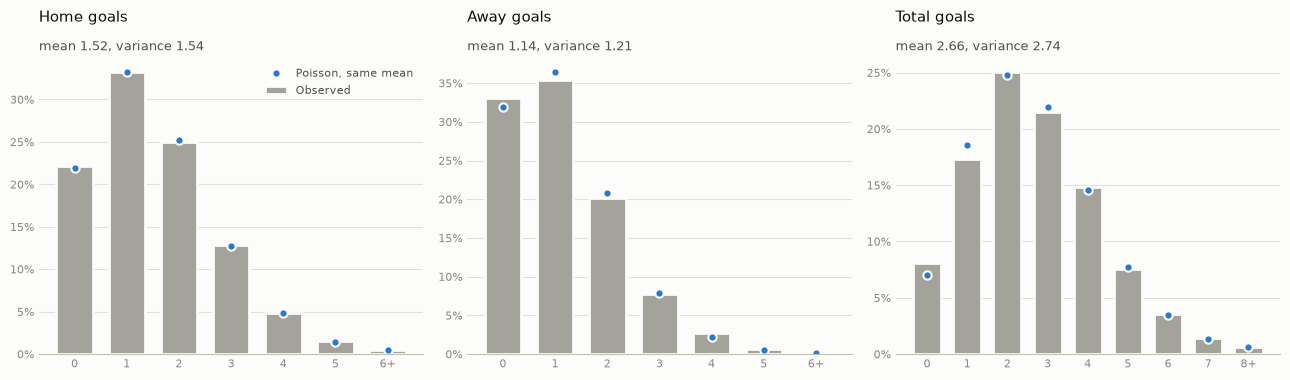

In [6]:
# Figure 46: observed goal distributions vs a Poisson with the same mean
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
fig.patch.set_facecolor(SURFACE)
for ax, (name, values) in zip(axes, goals.items()):
    top = 8 if name == "Total goals" else 6
    k = np.arange(top + 1)
    observed = np.array([(values == v).mean() for v in k[:-1]] + [(values >= top).mean()])
    fitted = np.r_[poisson.pmf(k[:-1], values.mean()), poisson.sf(top - 1, values.mean())]
    ax.bar(k, observed, width=0.7, color=NEUTRAL, edgecolor=SURFACE, linewidth=2, label="Observed")
    ax.plot(k, fitted, "o", color=COLORS[MODEL], markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5,
            label="Poisson, same mean")
    style_axes(ax)
    ax.set_xticks(k)
    ax.set_xticklabels([str(v) for v in k[:-1]] + [f"{top}+"])
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    set_title(ax, name, f"mean {values.mean():.2f}, variance {values.var(ddof=0):.2f}", size=11)
legend(axes[0], loc="upper right")
fig.tight_layout()
save_figure(fig, "46_goal_distributions_vs_poisson.png")
plt.show()

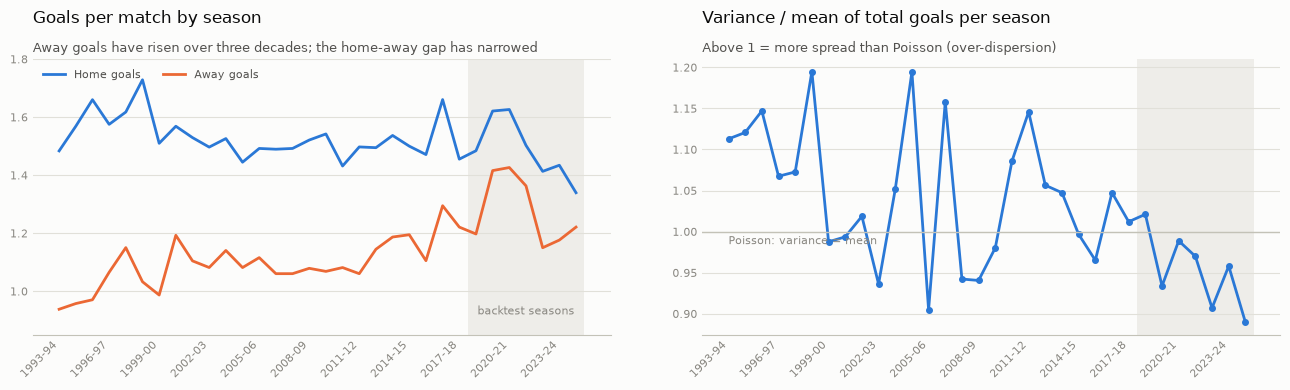

In [7]:
# Figure 47: goals per season and the variance-to-mean ratio
per_season = history.assign(total=history["home_goals"] + history["away_goals"]).groupby("season_start").agg(
    home=("home_goals", "mean"), away=("away_goals", "mean"), total=("total", "mean"),
    total_var=("total", lambda s: s.astype(float).var(ddof=0)))
per_season["ratio"] = per_season["total_var"] / per_season["total"]
per_season["draws"] = history.groupby("season_start").apply(lambda g: (g["home_goals"] == g["away_goals"]).mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
fig.patch.set_facecolor(SURFACE)
x = per_season.index
ax1.plot(x, per_season["home"], color=COLORS[MODEL], linewidth=2, label="Home goals")
ax1.plot(x, per_season["away"], color=COLORS[TEAM], linewidth=2, label="Away goals")
ax1.axvspan(2017.5, 2024.5, color=GRID, alpha=0.5, linewidth=0)
ax1.text(2021, 0.92, "backtest seasons", ha="center", fontsize=8, color=MUTED)
style_axes(ax1)
ax1.set_ylim(0.85, 1.8)
ax1.set_xticks(x[::3])
ax1.set_xticklabels([season_name(s) for s in x[::3]], rotation=45, ha="right")
set_title(ax1, "Goals per match by season", "Away goals have risen over three decades; the home-away gap has narrowed")
legend(ax1, loc="upper left", ncols=2)

ax2.plot(x, per_season["ratio"], color=COLORS[MODEL], linewidth=2, marker="o", markersize=4)
ax2.axhline(1, color=BASELINE_LINE, linewidth=1)
ax2.text(x.min(), 0.995, "Poisson: variance = mean", fontsize=8, color=MUTED, va="top")
ax2.axvspan(2017.5, 2024.5, color=GRID, alpha=0.5, linewidth=0)
style_axes(ax2)
ax2.set_xticks(x[::3])
ax2.set_xticklabels([season_name(s) for s in x[::3]], rotation=45, ha="right")
set_title(ax2, "Variance / mean of total goals per season", "Above 1 = more spread than Poisson (over-dispersion)")
fig.tight_layout()
save_figure(fig, "47_goals_by_season_and_dispersion.png")
plt.show()

**Interpretation**

- **A Poisson distribution describes Serie A goals well.** Over 11,346 matches, home goals have
  variance / mean 1.015, away goals 1.064 and total goals 1.031. A Poisson variable has exactly 1,
  so the extra spread is small. The per-season ratio swings between about 0.89 and 1.19 with no
  persistent over-dispersion; in the seven backtest seasons it is mostly *below* 1.
- **Home and away goals are almost uncorrelated** (-0.004), which supports the independence
  assumption *on average*. It does not show that they are independent *within* a fixture once the
  two teams' strengths are known; section 7 checks that.
- **More 0-0 and draws than one Poisson with a league-wide mean implies** (total = 0: 8.1% vs
  7.0%). Part of this is expected: real fixtures differ in strength, and a mixture of different
  rates has more zeros than a single rate. Draws are 27.5% of all matches.
- **The scoring level drifts.** Away goals per match rose from about 0.94 in 1993-94 to 1.2-1.4,
  and 2019-20 to 2021-22 were unusually high-scoring. A model trained on three decades of data has
  to cope with this drift, and so does the league-average baseline.

## 3. Predicted expected goals

**What each fold chose** (on S-1, after fitting on seasons up to S-2). The Poisson regression picks
a feature set (`goals`: the 30 goals-scored/conceded, previous-season and history features;
`compact`: the 22 features of the 1X2 models; `all`: all 50) and an L2 penalty `alpha` separately
for home and away goals. The team baseline picks how many recent matches count (`window`) and how
strongly they are shrunk toward the league average (`prior_matches`).

In [8]:
folds = experiment.folds.copy()
folds.insert(0, "evaluated", folds["season"].map(season_name))
columns = ["evaluated", "train_matches", "home_feature_set", "home_alpha", "away_feature_set", "away_alpha",
           "team_window", "team_prior_matches", "league_mu_home", "league_mu_away"]
display(folds[columns].style.format({"home_alpha": "{:g}", "away_alpha": "{:g}", "team_prior_matches": "{:g}",
                                     "league_mu_home": "{:.3f}", "league_mu_away": "{:.3f}", "train_matches": "{:,}"})
        .hide(axis="index").set_caption("Settings chosen in each fold (earlier seasons only)"))

evaluated,train_matches,home_feature_set,home_alpha,away_feature_set,away_alpha,team_window,team_prior_matches,league_mu_home,league_mu_away
2018-19,"8,686",goals,0.3,goals,0.0001,38,10,1.528,1.099
2019-20,"9,066",goals,1,all,3,38,30,1.526,1.103
2020-21,"9,446",goals,0.0001,goals,0.1,38,10,1.530,1.115
2021-22,"9,826",goals,0.1,goals,0.3,38,30,1.534,1.127
2022-23,"10,206",goals,3,goals,0.1,38,10,1.533,1.136
2023-24,"10,586",goals,0.03,compact,3,38,10,1.528,1.137
2024-25,"10,966",all,3,goals,0.0001,38,10,1.525,1.138


In [9]:
# The latest fold's model, refitted here exactly as in the backtest, to look at its coefficients
last = folds.iloc[-1]
latest = PoissonGoalsModel(SideChoice(last["home_feature_set"], float(last["home_alpha"])),
                           SideChoice(last["away_feature_set"], float(last["away_alpha"])))
latest.fit(features[features["season_start"] <= int(last["season"]) - 1])
coefficients = pd.DataFrame({side: latest.coefficients(side) for side in ("home", "away")})
top = coefficients.abs().max(axis=1).sort_values(ascending=False).index[:10]
display(coefficients.loc[top].style.format("{:+.3f}", na_rep="").set_caption(
    f"Largest coefficients (log scale, standardised inputs) of the {season_name(int(last['season']))} fold; "
    "blank = feature not in that side's set"))

,home,away
away_history_matches,-0.010,+0.066
home_form10_ga,-0.004,+0.063
away_prev_season_gd,-0.016,+0.056
away_season_gf,-0.009,+0.048
away_venue_form10_gf,-0.005,+0.045
home_form10_gf,+0.010,-0.039
home_prev_season_ppg,+0.021,-0.038
home_venue_form10_ga,+0.001,+0.037
home_season_ga,-0.009,+0.034
home_form5_gf,+0.009,+0.032


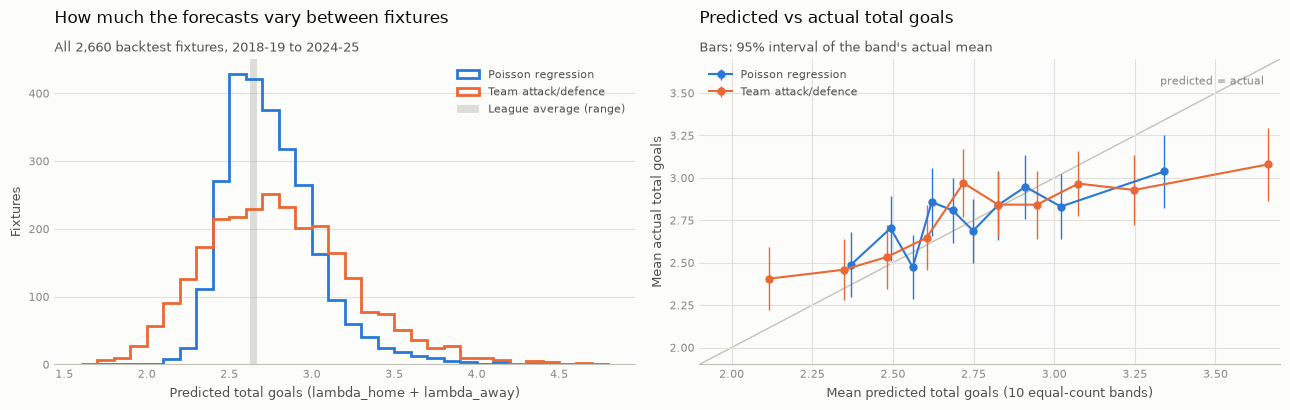

In [10]:
# Figure 48: spread of the predicted rates, and predicted vs actual total goals by band
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
fig.patch.set_facecolor(SURFACE)
lo = np.floor(predictions["lambda_total"].min() * 10) / 10
hi = np.ceil(predictions["lambda_total"].max() * 10) / 10
bins = np.arange(lo, hi + 0.1, 0.1)
for method in (MODEL, TEAM):
    rows = predictions[predictions["method"] == method]
    ax1.hist(rows["lambda_total"], bins=bins, histtype="step", linewidth=2, color=COLORS[method], label=method)
league_total = predictions.loc[predictions["method"] == LEAGUE, "lambda_total"]
ax1.axvspan(league_total.min(), league_total.max(), color=NEUTRAL, alpha=0.35, linewidth=0, label=LEAGUE + " (range)")
style_axes(ax1)
ax1.set_xlabel("Predicted total goals (lambda_home + lambda_away)", fontsize=9, color=INK_2)
ax1.set_ylabel("Fixtures", fontsize=9, color=INK_2)
set_title(ax1, "How much the forecasts vary between fixtures", "All 2,660 backtest fixtures, 2018-19 to 2024-25")
legend(ax1, loc="upper right")

for method in (MODEL, TEAM):
    band = goals_by_band(predictions, method)
    ax2.errorbar(band["predicted"], band["actual"], yerr=1.96 * band["se"], fmt="o-", color=COLORS[method],
                 markersize=5, linewidth=1.5, capsize=0, elinewidth=1, label=method)
lims = [1.9, 3.7]
ax2.plot(lims, lims, color=BASELINE_LINE, linewidth=1, zorder=0)
ax2.text(3.65, 3.55, "predicted = actual", fontsize=8, color=MUTED, ha="right")
style_axes(ax2, grid="both")
ax2.set_xlim(lims)
ax2.set_ylim(lims)
ax2.set_xlabel("Mean predicted total goals (10 equal-count bands)", fontsize=9, color=INK_2)
ax2.set_ylabel("Mean actual total goals", fontsize=9, color=INK_2)
set_title(ax2, "Predicted vs actual total goals", "Bars: 95% interval of the band's actual mean")
legend(ax2, loc="upper left")
fig.tight_layout()
save_figure(fig, "48_predicted_expected_goals.png")
plt.show()

**Interpretation**

- **The goals-focused feature set wins most choices.** It was picked in 11 of the 14 side-season
  choices. The team baseline always picked the 38-match window (about one season), shrunk by 10
  pseudo-matches (5 folds) or 30 (2 folds).
- **The chosen penalty jumps around** (alpha from 0.0001 to 3 between folds). The validation
  deviance is nearly flat across the grid, so this choice matters little. In the 2024-25 fold the
  coefficients are small: no single feature moves the expected goals by more than about 7% per
  standard deviation. That fold's away-goals model leans on the away club's Serie A experience, previous-season goal difference
  and season scoring rate, and on how many goals the home club has been conceding.
- **The forecasts spread more than the outcomes do.** The Poisson regression's predicted totals
  run from about 2.4 to 3.3 across the ten bands, but the actual mean only rises from about 2.5 to
  3.0. The team baseline spreads even more (2.1 to 3.7). Predicted total goals carry *some* signal
  (the actual mean rises with the forecast), but a forecast of 3.3 goals means about 3.0 in practice.

## 4. Historical performance versus baselines

All three methods are scored on exactly the same 2,660 fixtures. Lower is better for every score.
**Poisson deviance** is the natural score for expected goals: it is 0 when the rate equals the
goals scored and grows as they differ, penalising a confident miss more than an absolute error
does. It is reported as home + away. MAE is the mean absolute difference between goals and rate.

In [11]:
pooled = pooled_metrics(predictions)
goal_cols = {"matches": "Matches", "deviance": "Deviance (H+A)", "deviance_home": "Deviance home",
             "deviance_away": "Deviance away", "mae_home": "MAE home", "mae_away": "MAE away",
             "mean_lambda_home": "Pred. home", "mean_home_goals": "Actual home", "mean_lambda_away": "Pred. away",
             "mean_away_goals": "Actual away", "mean_lambda_total": "Pred. total", "mean_total_goals": "Actual total"}
display(pooled[list(goal_cols)].rename(columns=goal_cols).style.format("{:.3f}").format({"Matches": "{:,.0f}"})
        .set_caption("Pooled over 2018-19 to 2024-25 (identical fixtures)"))

,Matches,Deviance (H+A),Deviance home,Deviance away,MAE home,MAE away,Pred. home,Actual home,Pred. away,Actual away,Pred. total,Actual total
method,,,,,,,,,,,,
League average,"2,660",2.394330,1.172560,1.221770,1.009490,0.885796,1.529280,1.488722,1.122175,1.278571,2.651455,2.767293
Team attack/defence,"2,660",2.170337,1.072977,1.097361,0.939988,0.850276,1.613299,1.488722,1.189270,1.278571,2.802569,2.767293
Poisson regression,"2,660",2.146791,1.052569,1.094222,0.920464,0.851990,1.535933,1.488722,1.221642,1.278571,2.757575,2.767293


In [12]:
seasonal = season_metrics(predictions)
by_season = seasonal[["deviance", "mae_home", "mae_away", "mean_lambda_total", "mean_total_goals"]].unstack("method")
by_season.index = by_season.index.map(season_name)
display(by_season["deviance"][METHODS].style.format("{:.3f}").highlight_min(axis=1, props="font-weight: bold")
        .set_caption("Poisson deviance (home + away) per season; bold = best"))
totals = by_season["mean_lambda_total"][METHODS].copy()
totals["Actual"] = by_season["mean_total_goals"][MODEL]
display(totals.style.format("{:.2f}").set_caption("Mean predicted total goals per season, and the actual mean"))

method,League average,Team attack/defence,Poisson regression
season,,,
2018-19,2.420,2.255,2.239
2019-20,2.412,2.165,2.125
2020-21,2.488,2.211,2.176
2021-22,2.427,2.208,2.136
2022-23,2.300,2.128,2.103
2023-24,2.359,2.080,2.127
2024-25,2.354,2.146,2.121


method,League average,Team attack/defence,Poisson regression,Actual
season,,,,
2018-19,2.63,2.62,2.74,2.68
2019-20,2.63,2.83,2.72,3.04
2020-21,2.65,3.36,2.87,3.05
2021-22,2.66,2.99,2.85,2.87
2022-23,2.67,2.67,2.73,2.56
2023-24,2.67,2.55,2.68,2.61
2024-25,2.66,2.59,2.72,2.56


In [13]:
# Fixtures with a newly promoted (or returning) club: little or no Serie A history for that club
losses = match_losses(predictions)
losses["lambda_total"] = predictions["lambda_total"]
losses["total_goals"] = predictions["home_goals"] + predictions["away_goals"]
subgroup = losses.groupby(["promoted_club", "method"]).agg(
    matches=("deviance", "size"), deviance=("deviance", "mean"), log_loss_over_2_5=("log_loss_over_2_5", "mean"),
    log_loss_btts_yes=("log_loss_btts_yes", "mean"), predicted_total=("lambda_total", "mean"),
    actual_total=("total_goals", "mean"))
subgroup = subgroup.reindex(pd.MultiIndex.from_product([[False, True], METHODS], names=["promoted_club", "method"]))
display(subgroup.style.format("{:.4f}").format({"matches": "{:,.0f}", "predicted_total": "{:.2f}",
                                                 "actual_total": "{:.2f}"})
        .set_caption("Fixtures with and without a promoted club (pooled)"))

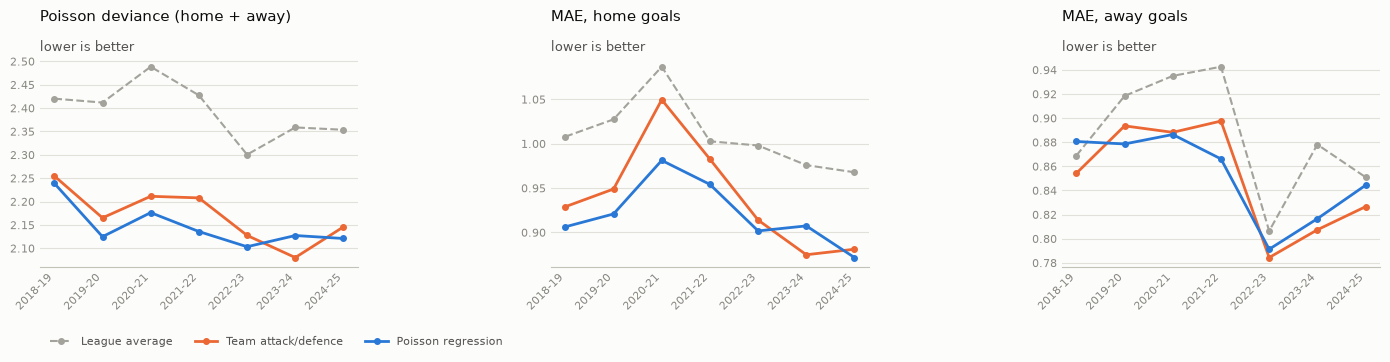

In [14]:
# Figure 49: expected-goals scores per season
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.patch.set_facecolor(SURFACE)
x = np.arange(len(BACKTEST_SEASONS))
panels = [("deviance", "Poisson deviance (home + away)"), ("mae_home", "MAE, home goals"), ("mae_away", "MAE, away goals")]
for ax, (metric, title) in zip(axes, panels):
    table = seasonal[metric].unstack("method")
    for method in METHODS:
        ax.plot(x, table[method].to_numpy(), marker="o", markersize=4, linewidth=2 if method != LEAGUE else 1.5,
                color=COLORS[method], label=method, linestyle="-" if method != LEAGUE else "--")
    style_axes(ax)
    ax.set_xticks(x)
    ax.set_xticklabels([SEASON_LABELS[s] for s in BACKTEST_SEASONS], rotation=45, ha="right")
    set_title(ax, title, "lower is better", size=11)
legend(axes[0], loc="upper left", bbox_to_anchor=(0, -0.28), ncols=3)
fig.tight_layout()
save_figure(fig, "49_expected_goals_by_season.png")
plt.show()

**Interpretation**

- **For expected goals, both team-aware methods are much better than the league average.**
  Pooled deviance (home + away) is 2.394 for the league average, 2.170 for the team baseline and
  2.147 for the Poisson regression: 10.3% better than the league average and 1.1% better than the
  team baseline. The Poisson regression beats the league average in all 7 seasons and the team
  baseline in 6 (not in 2023-24). Home-goal MAE falls from 1.009 to 0.920; away-goal MAE is a tie
  with the team baseline (0.852 vs 0.850).
- **The level is right overall but biased between home and away.** The mean predicted total is
  2.76 against 2.77 actual. Home goals are over-predicted (1.54 vs 1.49) and away goals
  under-predicted (1.22 vs 1.28). Home advantage in the training years (back to 1993-94) was larger
  than in the backtest seasons, and every season is weighted equally. The league average is too
  low overall (2.65), because it cannot react to the high-scoring 2019-20 to 2021-22 seasons.
- **Promoted clubs are not a weak spot.** Fixtures with a newly promoted or returning club (756
  of 2,660) score about as well as the rest; deviance is even lower for every method. The engineered features carry
  missing-history indicators, and the team baseline treats a club with no history as league average
  until it has played. The subgroup is small, so this only rules out a large problem.
- **Where the deviance gain comes from.** Deviance rewards getting each side's goals right, and
  much of that is knowing *which* side is stronger. The next two sections ask a different
  question: can the model forecast the *total* (Over/Under) and *both sides scoring* (BTTS)?

## 5. Over/Under probability quality

Each goal line is a yes/no event scored by **log loss** (`-log` of the probability given to what
happened) and **Brier score** (squared difference between probability and outcome). A forecast
that always says the long-run frequency is the natural floor: that is what the league average does,
up to the slow drift of goals between seasons.

In [15]:
event_cols = {f"log_loss_{e}": f"Log loss {label}" for e, label in EVENTS.items()}
event_cols |= {f"brier_{e}": f"Brier {label}" for e, label in EVENTS.items()}
ou = [c for c in event_cols if "btts" not in c]
display(pooled[ou].rename(columns=event_cols).T.style.format("{:.4f}").highlight_min(axis=1, props="font-weight: bold")
        .set_caption("Over/Under, pooled 2018-19 to 2024-25; bold = best"))

method,League average,Team attack/defence,Poisson regression
Log loss Over 0.5,0.2427,0.2449,0.2425
Log loss Over 1.5,0.5381,0.5353,0.5347
Log loss Over 2.5,0.6945,0.6918,0.6912
Log loss Over 3.5,0.6099,0.6089,0.6090
Brier Over 0.5,0.0615,0.0616,0.0614
Brier Over 1.5,0.1764,0.1753,0.1751
Brier Over 2.5,0.2507,0.2491,0.2490
Brier Over 3.5,0.2094,0.2092,0.2091


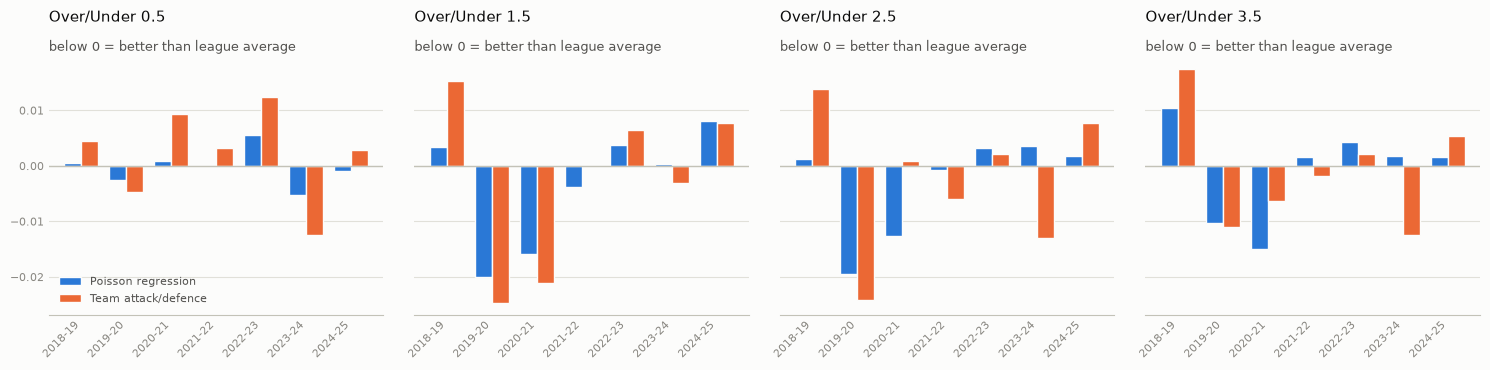

In [16]:
# Figure 50: per-season log loss difference to the league average, for every goal line
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
fig.patch.set_facecolor(SURFACE)
x = np.arange(len(BACKTEST_SEASONS))
for ax, line in zip(axes, (0.5, 1.5, 2.5, 3.5)):
    metric = f"log_loss_over_{str(line).replace('.', '_')}"
    table = seasonal[metric].unstack("method")
    width = 0.38
    for offset, method in ((-width / 2, MODEL), (width / 2, TEAM)):
        diff = (table[method] - table[LEAGUE]).to_numpy()
        ax.bar(x + offset, diff, width=width, color=COLORS[method], edgecolor=SURFACE, linewidth=1, label=method)
    ax.axhline(0, color=BASELINE_LINE, linewidth=1)
    style_axes(ax)
    ax.set_xticks(x)
    ax.set_xticklabels([SEASON_LABELS[s] for s in BACKTEST_SEASONS], rotation=45, ha="right")
    set_title(ax, f"Over/Under {line}", "below 0 = better than league average", size=11)
legend(axes[0], loc="lower left")
fig.tight_layout()
save_figure(fig, "50_over_under_by_season.png")
plt.show()

### A yardstick: the betting market on Over/Under 2.5

The raw Football-Data files already on disk contain **market-average pre-match Over/Under 2.5
odds** (`BbAv` in 2018-19, `Avg` from 2019-20). They are converted to probabilities by removing the
margin proportionally. They are used *only* to judge the forecasts, never as a feature, and only
for the 2.5 line (no other line or BTTS odds are in the data). Bookmakers see team news, lineups
and money flows that our features do not, so beating them is not the bar for the app; they show how
much information a goals forecast can contain.

In [17]:
coverage = market_coverage(predictions, odds)
coverage.index = coverage.index.map(season_name)
display(coverage.style.format({"coverage": "{:.1%}", "mean_overround": "{:.1%}"})
        .set_caption("Fixtures with market Over/Under 2.5 odds"))
market = market_comparison(predictions, odds, n_resamples=N_RESAMPLES)
display(market.style.format("{:.4f}", na_rep="").format({"matches": "{:,.0f}", "mean_predicted": "{:.1%}",
                                                         "observed": "{:.1%}"})
        .set_caption("Over/Under 2.5 on the fixtures with odds; log_loss_vs_market > 0 = worse than the market"))

,fixtures,with_odds,source,mean_overround,coverage
season,,,,,
2018-19,380,380,BbAv,5.6%,100.0%
2019-20,380,380,Avg,5.4%,100.0%
2020-21,380,379,Avg,5.4%,99.7%
2021-22,380,379,Avg,5.0%,99.7%
2022-23,380,380,Avg,4.9%,100.0%
2023-24,380,380,Avg,4.8%,100.0%
2024-25,380,380,Avg,4.9%,100.0%


,matches,log_loss,brier,mean_predicted,observed,log_loss_vs_market,ci_low,ci_high
method,,,,,,,,
League average,"2,658",0.694489,0.250671,49.4%,52.9%,0.015923,0.009741,0.022083
Team attack/defence,"2,658",0.691755,0.249053,52.5%,52.9%,0.013189,0.007856,0.018513
Poisson regression,"2,658",0.691175,0.248958,51.8%,52.9%,0.012609,0.007764,0.017460
Market average (O/U 2.5),"2,658",0.678566,0.242732,52.5%,52.9%,nan,nan,nan


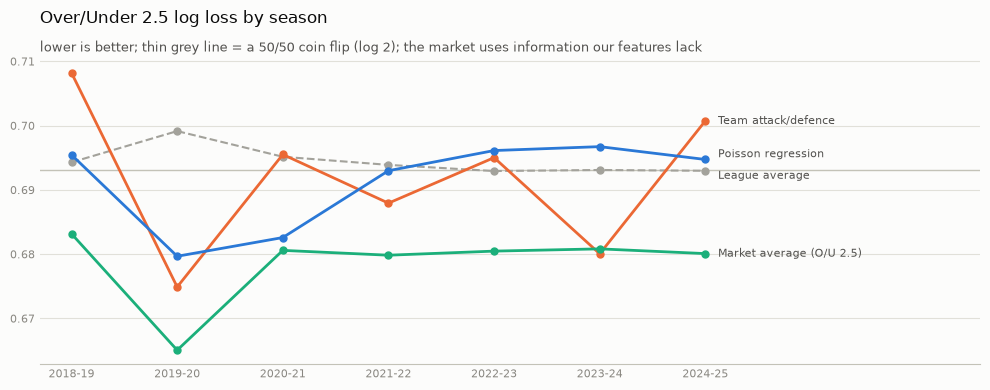

In [18]:
# Figure 51: Over/Under 2.5 log loss per season, all forecasts including the market
long = market_predictions(predictions, odds)
table = long.groupby(["season", "method"])["log_loss_over_2_5"].mean().unstack("method")
fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor(SURFACE)
x = np.arange(len(table))
for method in [LEAGUE, TEAM, MODEL, MARKET]:
    ax.plot(x, table[method].to_numpy(), marker="o", markersize=5, linewidth=2 if method != LEAGUE else 1.5,
            linestyle="--" if method == LEAGUE else "-", color=COLORS[method], label=method)
    nudge = {MODEL: 0.0008, LEAGUE: -0.0008}.get(method, 0.0)  # keep the two close labels apart
    ax.text(x[-1] + 0.12, table[method].iloc[-1] + nudge, method, fontsize=8, color=INK_2, va="center")
ax.axhline(np.log(2), color=BASELINE_LINE, linewidth=1, zorder=0)
style_axes(ax)
ax.set_xlim(-0.3, len(table) + 1.6)
ax.set_xticks(x)
ax.set_xticklabels([season_name(s) for s in table.index])
set_title(ax, "Over/Under 2.5 log loss by season",
          "lower is better; thin grey line = a 50/50 coin flip (log 2); the market uses information our features lack")
fig.tight_layout()
save_figure(fig, "51_over_under_2_5_vs_market.png")
plt.show()

**Interpretation**

- **Over/Under barely improves on the league average.** Pooled Over 2.5 log loss is 0.6945
  (league average), 0.6918 (team) and 0.6912 (Poisson regression): a 0.5% improvement, just below
  a 50/50 coin flip (0.6931). Over 1.5 shows a similar small gain (0.5381 to 0.5347). Over 0.5 and
  Over 3.5 are effectively tied.
- **The small gain comes from two seasons.** In the high-scoring 2019-20 and 2020-21 seasons the
  league average (trained on lower-scoring years) predicted too few goals, and both team-aware
  methods did better. In the other seasons the Poisson regression is usually slightly *worse* than
  the league average on Over 2.5 (Figure 50). It wins 3 of 7 seasons.
- **The betting market is clearly better.** On the 2,658 fixtures with odds (99.9% coverage,
  margin 4.8-5.6%), the market's Over 2.5 log loss is 0.6786. The Poisson regression is 0.0126
  worse (95% interval 0.0078 to 0.0175) and is worse than the market in every season. The team
  baseline only edges the market once, in 2023-24, by less than 0.001.
  The market knows lineups, injuries, weather and team news that pre-match features from past
  results do not.

## 6. BTTS probability quality

BTTS Yes needs *both* sides to score, so it depends on both rates at once:
`(1 - exp(-λ_home)) * (1 - exp(-λ_away))`. There are no BTTS odds in the data, so the comparison
is with the two baselines only.

In [19]:
btts = seasonal[["log_loss_btts_yes", "brier_btts_yes"]].unstack("method")
outcomes = event_outcomes(predictions)
mean_p = predictions.groupby(["season", "method"])["btts_yes"].mean().unstack("method")
observed = outcomes[predictions["method"] == MODEL].groupby(predictions["season"])["btts_yes"].mean()
view = pd.concat({"log loss": btts["log_loss_btts_yes"][METHODS], "mean predicted": mean_p[METHODS],
                  "observed": observed.rename("BTTS Yes").to_frame()}, axis=1)
view.index = view.index.map(season_name)
display(view.style.format("{:.4f}").format("{:.1%}", subset=[c for c in view.columns if c[0] != "log loss"])
        .set_caption("BTTS Yes per season"))
display(pooled[["log_loss_btts_yes", "brier_btts_yes"]].style.format("{:.4f}").set_caption("BTTS, pooled"))

,log_loss_btts_yes,brier_btts_yes
method,,
League average,0.6892,0.2480
Team attack/defence,0.6895,0.2481
Poisson regression,0.6900,0.2484


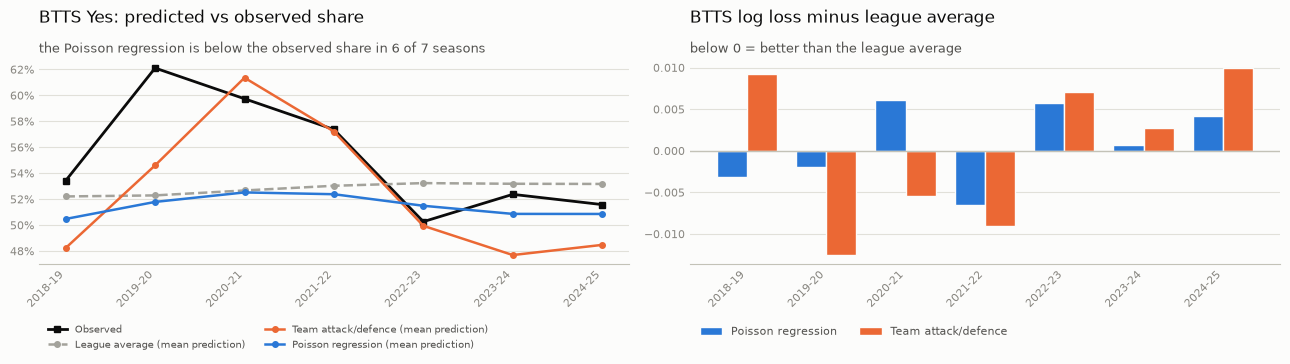

In [20]:
# Figure 52: BTTS per season - mean predicted vs observed, and log loss vs league average
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
fig.patch.set_facecolor(SURFACE)
x = np.arange(len(BACKTEST_SEASONS))
ax1.plot(x, observed.to_numpy(), color=INK, linewidth=2, marker="s", markersize=5, label="Observed")
for method in METHODS:
    ax1.plot(x, mean_p[method].to_numpy(), marker="o", markersize=4, linewidth=1.8, color=COLORS[method],
             linestyle="--" if method == LEAGUE else "-", label=f"{method} (mean prediction)")
style_axes(ax1)
ax1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax1.set_xticks(x)
ax1.set_xticklabels([SEASON_LABELS[s] for s in BACKTEST_SEASONS], rotation=45, ha="right")
below = int((mean_p[MODEL] < observed).sum())
set_title(ax1, "BTTS Yes: predicted vs observed share",
          f"the Poisson regression is below the observed share in {below} of {len(observed)} seasons")
legend(ax1, loc="upper left", bbox_to_anchor=(0, -0.25), ncols=2, fontsize=7)

width = 0.38
for offset, method in ((-width / 2, MODEL), (width / 2, TEAM)):
    diff = (btts["log_loss_btts_yes"][method] - btts["log_loss_btts_yes"][LEAGUE]).to_numpy()
    ax2.bar(x + offset, diff, width=width, color=COLORS[method], edgecolor=SURFACE, linewidth=1, label=method)
ax2.axhline(0, color=BASELINE_LINE, linewidth=1)
style_axes(ax2)
ax2.set_xticks(x)
ax2.set_xticklabels([SEASON_LABELS[s] for s in BACKTEST_SEASONS], rotation=45, ha="right")
set_title(ax2, "BTTS log loss minus league average", "below 0 = better than the league average")
legend(ax2, loc="upper left", bbox_to_anchor=(0, -0.25), ncols=2)
fig.tight_layout()
save_figure(fig, "52_btts_by_season.png")
plt.show()

**Interpretation**

- **BTTS is not better than the league average.** Pooled log loss is 0.6892 (league average),
  0.6895 (team) and 0.6900 (Poisson regression), all practically at the coin-flip level of 0.6931.
- **BTTS is under-predicted.** The Poisson regression's mean BTTS probability is 51.5%, but both
  teams scored in 55.3% of the matches. That is too low in 6 of the 7 seasons, by as much as 10
  points in 2019-20. Two reasons, both checked in section 7:
  1. away goals are under-predicted (section 4), which lowers `P(away side scores)`;
  2. the independence assumption misses a small positive dependence between the two sides' goals
     that raises draws and BTTS.

## 7. Calibration analysis

A forecast is **calibrated** when events given 60% happen about 60% of the time. Three views:

* **Calibration in the large:** mean probability vs observed frequency over all fixtures.
* **Reliability bins:** the fixtures are split into 10 equal-count bins by predicted probability;
  each bin's observed frequency has a 95% Wilson interval (about ±6 points with 266 fixtures).
* **Calibration slope:** a logistic regression of the outcome on `logit(p)`. A slope of 1 is ideal;
  below 1 means the probabilities vary *more* than the outcomes justify (too extreme), above 1
  too timid. It is not estimated for the league average, which barely varies.

In [21]:
calibration = calibration_table(predictions)
view = calibration.pivot(index="label", columns="method",
                         values=["mean_predicted", "observed", "difference", "ece", "bins_outside", "calibration_slope"])
view = view.reindex([EVENTS[e] for e in EVENTS])
stats = ["mean_predicted", "observed", "difference", "ece", "bins_outside", "calibration_slope"]
view = view.reindex(columns=pd.MultiIndex.from_product([stats, METHODS]))
fmt = {c: "{:+.1%}" for c in view.columns if c[0] == "difference"}
fmt |= {c: "{:.1%}" for c in view.columns if c[0] in ("mean_predicted", "observed", "ece")}
fmt |= {c: "{:.2f}" for c in view.columns if c[0] == "calibration_slope"}
fmt |= {c: "{:.0f}" for c in view.columns if c[0] == "bins_outside"}
display(view.style.format(fmt, na_rep="-").set_caption(
    "Calibration of every event (difference = mean predicted - observed; bins_outside of 10)"))

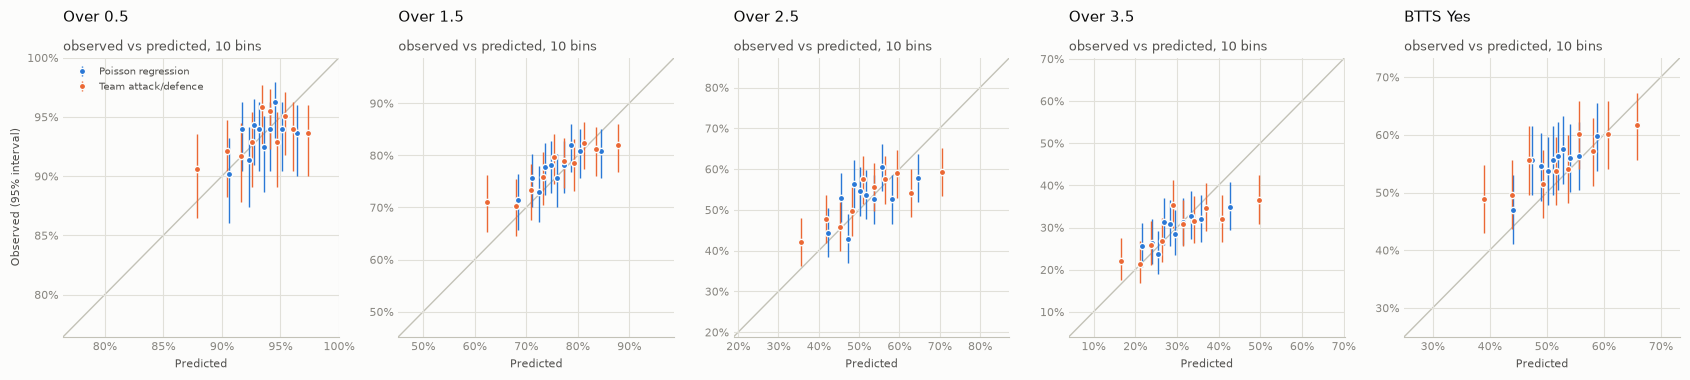

In [22]:
# Figure 53: reliability diagrams
fig, axes = plt.subplots(1, 5, figsize=(17, 3.9))
fig.patch.set_facecolor(SURFACE)
for ax, (event, label) in zip(axes, EVENTS.items()):
    for method in (MODEL, TEAM):
        mask = predictions["method"] == method
        table = reliability_table(predictions.loc[mask, event], outcomes.loc[mask, event])
        ax.errorbar(table["mean_predicted"], table["observed"],
                    yerr=[table["observed"] - table["ci_low"], table["ci_high"] - table["observed"]],
                    fmt="o", color=COLORS[method], markersize=4.5, elinewidth=1, capsize=0, label=method,
                    markeredgecolor=SURFACE, markeredgewidth=1)
    p = predictions.loc[predictions["method"] == MODEL, event]
    lo, hi = max(0, p.min() - 0.05), min(1, p.max() + 0.05)
    ax.plot([lo, hi], [lo, hi], color=BASELINE_LINE, linewidth=1, zorder=0)
    style_axes(ax, grid="both")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Predicted", fontsize=8, color=INK_2)
    set_title(ax, label, "observed vs predicted, 10 bins", size=11)
axes[0].set_ylabel("Observed (95% interval)", fontsize=8, color=INK_2)
legend(axes[0], loc="upper left", fontsize=7)
fig.tight_layout()
save_figure(fig, "53_goals_reliability.png")
plt.show()

### Systematic over- or under-prediction

Does the model expect too many high-scoring games, draws or BTTS? `expected` is the mean
probability over all 2,660 fixtures, `observed` the share that happened, with a 95% interval.
Draws, home wins and away wins come from the score grid (evaluation only).

In [23]:
bias = bias_table(predictions)
view = bias.pivot(index="event", columns="method", values="difference")[METHODS]
view = view.reindex(bias["event"].unique())
observed_share = bias[bias["method"] == MODEL].set_index("event")[["observed", "ci_low", "ci_high"]]
display(pd.concat([observed_share, view], axis=1).style.format("{:.1%}").format("{:+.1%}", subset=METHODS)
        .set_caption("Expected minus observed (positive = predicted too often)"))

,observed,ci_low,ci_high,League average,Team attack/defence,Poisson regression
event,,,,,,
4+ goals (Over 3.5),29.7%,28.0%,31.5%,-2.2%,+1.3%,+0.2%
5+ goals (Over 4.5),14.4%,13.1%,15.7%,-1.4%,+1.5%,+0.5%
0-1 goals (Under 1.5),22.7%,21.1%,24.3%,+3.1%,+1.4%,+1.6%
Draw,26.6%,25.0%,28.3%,-1.2%,-3.0%,-3.2%
0-0,6.6%,5.7%,7.6%,+0.5%,+0.1%,-0.0%
BTTS Yes,55.3%,53.4%,57.1%,-2.4%,-2.8%,-3.8%
Home win,41.3%,39.4%,43.2%,+5.4%,+5.7%,+3.5%
Away win,32.1%,30.4%,33.9%,-4.2%,-2.7%,-0.3%


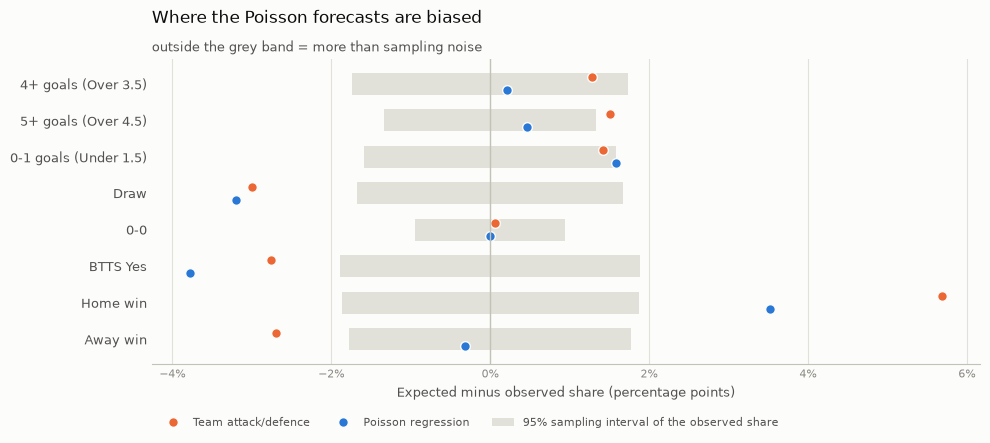

In [24]:
# Figure 54: expected minus observed, with the sampling interval of the observed share
fig, ax = plt.subplots(figsize=(10, 4.6))
fig.patch.set_facecolor(SURFACE)
events = list(bias["event"].unique())
y = np.arange(len(events))
rows = bias[bias["method"] == MODEL].set_index("event").loc[events]
half = (rows["ci_high"] - rows["ci_low"]) / 2
ax.barh(y, 2 * half, left=-half, height=0.6, color=GRID, label="95% sampling interval of the observed share")
for offset, method in ((-0.18, TEAM), (0.18, MODEL)):
    diff = bias[bias["method"] == method].set_index("event").loc[events, "difference"]
    ax.plot(diff, y + offset, "o", color=COLORS[method], markersize=7, markeredgecolor=SURFACE, label=method)
ax.axvline(0, color=BASELINE_LINE, linewidth=1)
style_axes(ax, grid="x")
ax.set_yticks(y)
ax.set_yticklabels(events, color=INK_2, fontsize=9)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Expected minus observed share (percentage points)", fontsize=9, color=INK_2)
set_title(ax, "Where the Poisson forecasts are biased", "outside the grey band = more than sampling noise")
legend(ax, loc="upper left", bbox_to_anchor=(0, -0.14), ncols=3)
fig.tight_layout()
save_figure(fig, "54_goals_bias.png")
plt.show()

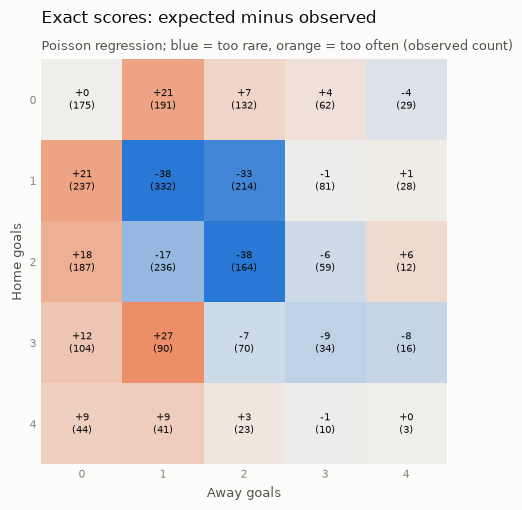

Scores with 5+ goals for a side: expected 111, observed 86


In [25]:
# Figure 55: exact scores - expected minus observed counts
scores = score_frequency_table(predictions, MODEL)
grid_scores = scores[scores["score"] != "other"]
diff = grid_scores.pivot(index="home_goals", columns="away_goals", values="difference")
obs = grid_scores.pivot(index="home_goals", columns="away_goals", values="observed")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
fig.patch.set_facecolor(SURFACE)
limit = np.abs(diff.to_numpy()).max()
ax.imshow(diff.to_numpy(), cmap=DIVERGING, vmin=-limit, vmax=limit)
for h in diff.index:
    for a in diff.columns:
        ax.text(a, h, f"{int(round(diff.loc[h, a])):+d}\n({obs.loc[h, a]:.0f})", ha="center", va="center", fontsize=7.5, color=INK)
ax.set_xticks(range(len(diff.columns)))
ax.set_yticks(range(len(diff.index)))
ax.tick_params(colors=MUTED, labelsize=8, length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_xlabel("Away goals", fontsize=9, color=INK_2)
ax.set_ylabel("Home goals", fontsize=9, color=INK_2)
set_title(ax, "Exact scores: expected minus observed", "Poisson regression; blue = too rare, orange = too often (observed count)")
fig.tight_layout()
save_figure(fig, "55_exact_score_differences.png")
plt.show()
other = scores[scores["score"] == "other"].iloc[0]
print(f"Scores with 5+ goals for a side: expected {other['expected']:.0f}, observed {other['observed']:.0f}")

In [26]:
dispersion = dispersion_table(predictions)
cols = ["home_variance_ratio", "away_variance_ratio", "total_variance_ratio", "goals_correlation", "residual_correlation"]
display(dispersion[cols].style.format("{:.3f}").set_caption(
    "Variance ratio = observed variance / variance the method implies (1 = Poisson-consistent); "
    "residual correlation of (goals - lambda) between home and away"))

,home_variance_ratio,away_variance_ratio,total_variance_ratio,goals_correlation,residual_correlation
method,,,,,
League average,0.997,1.191,1.010,-0.064,-0.063
Team attack/defence,0.832,1.023,0.894,-0.064,0.048
Poisson regression,0.873,0.977,0.945,-0.064,0.051


**Interpretation**

- **The goal lines are roughly calibrated on average.** The Poisson regression's mean probability
  is within 1.6 points of the observed share for every line (Over 0.5 +0.0, Over 1.5 -1.6,
  Over 2.5 -1.1, Over 3.5 +0.2). BTTS is 3.8 points too low, the largest miss of any event.
- **The probabilities are too extreme.** Calibration slopes are 0.46-0.62 for the Poisson
  regression and 0.31-0.51 for the team baseline, against an ideal of 1. The forecasts move further
  from the average than the outcomes justify, matching Figure 48. Over 2.5 has 3 of 10 reliability
  bins outside their 95% interval.
- **High-scoring games are fine; draws are not.** 4+ and 5+ goal matches are predicted within
  half a point and 0-0 almost exactly. But draws are under-predicted by 3.2 points (23.4% vs 26.6%).
  The exact-score grid shows where: 1-1 (-38 matches), 2-2 (-38) and 1-2 (-33) happen more often
  than the model expects, while 1-0, 0-1, 2-0 and 3-1 happen less often. This is the pattern that
  Dixon-Coles style adjustments and bivariate Poisson models are designed for.
- **Home wins are over-predicted by 3.5 points**, again the home-advantage drift from section 4.
- **No sign of over-dispersion.** Observed goal variance is *below* what the model implies
  (ratio 0.95 for total goals), because the predicted rates themselves spread too much. Variance
  beyond Poisson is not this model's problem here. The residual correlation of home and away goals
  given the forecast is +0.05: small, but in the direction that produces extra draws and BTTS.
- **This is a model limitation, not a calculation error.** The probabilities are exact for the
  stated assumptions (tested against closed forms and the Skellam distribution). So Dixon-Coles
  and bivariate Poisson are left for a future experiment, as planned.

## 8. Statistical uncertainty

Differences of a few thousandths of a log-loss unit can easily be noise. For each comparison of the
Poisson regression with a baseline, the per-match differences on identical fixtures are resampled
10,000 times (paired bootstrap).

**Multiple comparisons.** The family is 22 comparisons: two baselines × 11 headline scores
(deviance, plus log loss and Brier for the four lines and BTTS). The table shows the ordinary 95%
interval, a **Bonferroni-adjusted** interval (confidence 1 - 0.05/22) and a Holm-adjusted p-value.
Only an adjusted interval that excludes 0 counts as an established difference. The three
**primary** scores of the decision rule are marked.

In [27]:
comparisons = paired_comparisons(predictions, n_resamples=N_RESAMPLES)
view = comparisons[["baseline", "label", "primary", "difference", "relative", "ci_low", "ci_high", "adj_ci_low",
                    "adj_ci_high", "p_holm", "adjusted_interval_excludes_zero"]]
display(view.style.format({"difference": "{:+.4f}", "relative": "{:+.2%}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}",
                           "adj_ci_low": "{:+.4f}", "adj_ci_high": "{:+.4f}", "p_holm": "{:.4f}"})
        .hide(axis="index").set_caption("Poisson regression minus baseline, pooled (negative = Poisson better)"))

baseline,label,primary,difference,relative,ci_low,ci_high,adj_ci_low,adj_ci_high,p_holm,adjusted_interval_excludes_zero
League average,Poisson deviance (home + away),True,-0.2475,-10.34%,-0.2852,-0.2103,-0.3076,-0.1907,0.0022,True
League average,"Log loss, Over 0.5",False,-0.0003,-0.12%,-0.0029,+0.0025,-0.0044,+0.0043,1.0000,False
League average,"Log loss, Over 1.5",False,-0.0034,-0.64%,-0.0076,+0.0009,-0.0100,+0.0034,1.0000,False
League average,"Log loss, Over 2.5",True,-0.0033,-0.48%,-0.0086,+0.0019,-0.0120,+0.0049,1.0000,False
League average,"Log loss, Over 3.5",False,-0.0009,-0.14%,-0.0063,+0.0047,-0.0092,+0.0076,1.0000,False
League average,"Log loss, BTTS Yes",True,+0.0007,+0.11%,-0.0026,+0.0040,-0.0045,+0.0056,1.0000,False
League average,"Brier, Over 0.5",False,-0.0000,-0.07%,-0.0003,+0.0003,-0.0005,+0.0005,1.0000,False
League average,"Brier, Over 1.5",False,-0.0013,-0.72%,-0.0027,+0.0002,-0.0035,+0.0011,1.0000,False
League average,"Brier, Over 2.5",False,-0.0017,-0.68%,-0.0043,+0.0008,-0.0059,+0.0023,1.0000,False
League average,"Brier, Over 3.5",False,-0.0004,-0.18%,-0.0027,+0.0020,-0.0040,+0.0033,1.0000,False


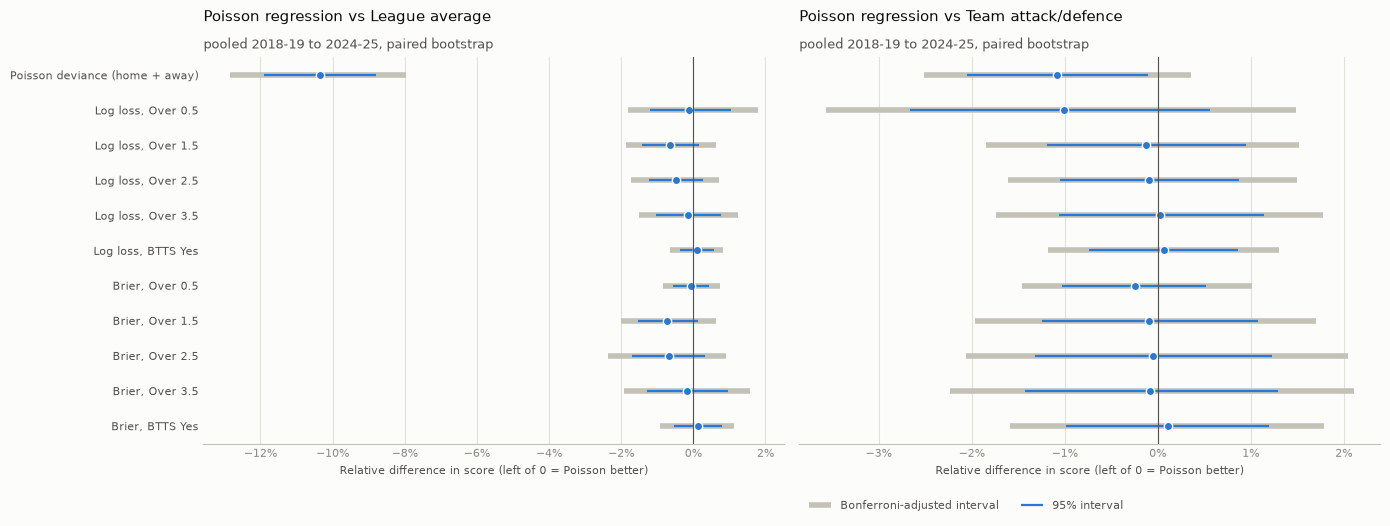

In [28]:
# Figure 56: forest plot of the relative differences (difference / baseline score)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
fig.patch.set_facecolor(SURFACE)
labels = [metric_label(m) for m in HEADLINE_METRICS]
y = np.arange(len(labels))
for ax, baseline in zip(axes, BASELINES):
    rows = comparisons[comparisons["baseline"] == baseline].set_index("metric").loc[HEADLINE_METRICS]
    base = pooled.loc[baseline, HEADLINE_METRICS].to_numpy()
    ax.hlines(y, rows["adj_ci_low"] / base, rows["adj_ci_high"] / base, color=BASELINE_LINE, linewidth=4,
              label="Bonferroni-adjusted interval")
    ax.hlines(y, rows["ci_low"] / base, rows["ci_high"] / base, color=COLORS[MODEL], linewidth=1.6,
              label="95% interval")
    ax.plot(rows["relative"], y, "o", color=COLORS[MODEL], markersize=6, markeredgecolor=SURFACE)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    style_axes(ax, grid="x")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=8, color=INK_2)
    ax.set_xlabel("Relative difference in score (left of 0 = Poisson better)", fontsize=8, color=INK_2)
    set_title(ax, f"Poisson regression vs {baseline}", "pooled 2018-19 to 2024-25, paired bootstrap", size=11)
axes[0].invert_yaxis()
legend(axes[1], loc="upper left", bbox_to_anchor=(0, -0.12), ncols=2)
fig.tight_layout()
save_figure(fig, "56_goals_paired_intervals.png")
plt.show()

### Sensitivity: related matches and single seasons

* **Week clusters.** The bootstrap above treats matches as independent. Matches on the same weekend
  share conditions (weather, fixture congestion, scoring trends), so the intervals are recomputed
  resampling whole weeks instead of single matches.
* **Season level.** Seven seasons are seven largely independent repetitions. How many does the
  Poisson model win, and does the pooled result survive dropping any single season?

In [29]:
clustered = paired_comparisons(predictions, metrics=PRIMARY_METRICS, n_resamples=N_RESAMPLES, cluster="week",
                               n_comparisons=len(HEADLINE_METRICS) * len(BASELINES))
merged = comparisons[comparisons["primary"]].merge(clustered, on=["baseline", "metric"], suffixes=("", "_week"))
shown = merged[["baseline", "label", "difference", "ci_low", "ci_high", "ci_low_week", "ci_high_week",
                "adj_ci_high", "adj_ci_high_week"]]
display(shown.style.format("{:+.4f}", subset=list(shown.columns[2:]))
        .hide(axis="index").set_caption("Primary scores: match-level vs week-cluster bootstrap"))
sensitivity = season_sensitivity(predictions)
display(sensitivity.drop(columns=["metric"]).style.format({c: "{:+.4f}" for c in sensitivity.columns
                                                           if "difference" in c or "leave" in c})
        .format({"sign_test_p": "{:.3f}"}).hide(axis="index")
        .set_caption("Season-level sensitivity (negative = Poisson better)"))

baseline,label,difference,ci_low,ci_high,ci_low_week,ci_high_week,adj_ci_high,adj_ci_high_week
League average,Poisson deviance (home + away),-0.2475,-0.2852,-0.2103,-0.2833,-0.2118,-0.1907,-0.1945
League average,"Log loss, Over 2.5",-0.0033,-0.0086,+0.0019,-0.0087,+0.0020,+0.0049,+0.0053
League average,"Log loss, BTTS Yes",+0.0007,-0.0026,+0.0040,-0.0024,+0.0038,+0.0056,+0.0057
Team attack/defence,Poisson deviance (home + away),-0.0235,-0.0445,-0.0023,-0.0457,-0.0015,+0.0078,+0.0106
Team attack/defence,"Log loss, Over 2.5",-0.0006,-0.0073,+0.0060,-0.0074,+0.0060,+0.0104,+0.0098
Team attack/defence,"Log loss, BTTS Yes",+0.0005,-0.0051,+0.0060,-0.0050,+0.0060,+0.0090,+0.0091


baseline,label,seasons,seasons_better,sign_test_p,pooled_difference,mean_season_difference,best_season_difference,worst_season_difference,leave_one_out_min,leave_one_out_max
League average,Poisson deviance (home + away),7,7,0.016,-0.247539,-0.247539,-0.312202,-0.181081,-0.258616,-0.236762
League average,"Log loss, Over 2.5",7,3,1.000,-0.003318,-0.003318,-0.019476,0.003633,-0.004477,-0.000625
League average,"Log loss, BTTS Yes",7,3,1.000,0.000727,0.000727,-0.006525,0.006099,-0.000168,0.001936
Team attack/defence,Poisson deviance (home + away),7,6,0.125,-0.023546,-0.023546,-0.071968,0.047143,-0.035328,-0.015476
Team attack/defence,"Log loss, Over 2.5",7,3,1.000,-0.000645,-0.000645,-0.013573,0.016670,-0.003531,0.001509
Team attack/defence,"Log loss, BTTS Yes",7,4,1.000,0.000460,0.000460,-0.012425,0.011559,-0.001390,0.002607


### Context: 1X2 from the score distribution

The score grid also gives home-win / draw / away-win probabilities. They are **for evaluation only**
(the production 1X2 models are not changed). Compared on the same fixtures with the 1X2 Logistic
Regression from the walk-forward backtest (`outputs/backtest/`), if that run is available:

In [30]:
losses = match_losses(predictions)
summary_1x2 = losses.groupby("method")[["log_loss_1x2", "brier_1x2", "log_loss_exact_score"]].mean().reindex(METHODS)
if (BACKTEST_DIR / "predictions.csv").exists():
    lr = load_backtest().predictions
    lr = lr[lr["forecast"] == "Logistic Regression"][["date", "home_team", "away_team", "actual", *OUTCOMES]]
    mine = predictions[predictions["method"] == MODEL][["date", "home_team", "away_team", *OUTCOMES]]
    both = mine.merge(lr, on=["date", "home_team", "away_team"], suffixes=("_poisson", "_lr"), validate="one_to_one")
    pois = per_match_log_loss(both["actual"], both[[f"{o}_poisson" for o in OUTCOMES]].set_axis(OUTCOMES, axis=1))
    logi = per_match_log_loss(both["actual"], both[[f"{o}_lr" for o in OUTCOMES]].set_axis(OUTCOMES, axis=1))
    print(f"{len(both):,} common fixtures: 1X2 log loss Poisson grid {pois.mean():.4f} vs Logistic Regression {logi.mean():.4f}")
display(summary_1x2.style.format("{:.4f}").set_caption("1X2 and exact-score log loss from the score grid (all 2,660 fixtures)"))

2,660 common fixtures: 1X2 log loss Poisson grid 0.9862 vs Logistic Regression 0.9834


,log_loss_1x2,brier_1x2,log_loss_exact_score
method,,,
League average,1.0889,0.6605,3.0110
Team attack/defence,0.9967,0.5949,2.8990
Poisson regression,0.9862,0.5873,2.8872


**Interpretation**

- **Only one comparison is established:** expected-goals deviance against the league average
  (-0.248, adjusted interval -0.308 to -0.191, Holm p = 0.002). It holds in all 7 seasons and
  when any one season is left out.
- **Against the team baseline, the deviance gain is suggestive, not established.** The ordinary
  95% interval excludes 0 (-0.045 to -0.002), but the Bonferroni-adjusted interval does not
  (-0.055 to +0.008), and the Holm p-value is 0.64. It holds in 6 of 7 seasons (sign test
  p = 0.125) and survives leaving out any one season.
- **None of the 20 Over/Under and BTTS comparisons is distinguishable from zero,** even without
  any adjustment for multiple comparisons. The differences are a few thousandths of a log-loss
  unit, and seasons split roughly 3-4 either way.
- **Related matches do not change the picture:** resampling whole weeks gives almost the same
  intervals as resampling matches.
- **1X2 from the score grid is close to the production Logistic Regression** (log loss 0.9862 vs
  0.9834 on the same 2,660 fixtures). This is consistent with the deviance gain being mostly about
  relative team strength. It is shown for context only; the 1X2 models are unchanged.

## 9. Conclusions and recommendation

The decision rule was written down in `src/goals_backtest.py` **before** the experiment was run.
The goals model is ready for the app only if all of these hold:

1. **Skill:** against the league average, the Bonferroni-adjusted interval is below 0 for the three
   primary scores (deviance, Over/Under 2.5 log loss, BTTS log loss);
2. **Stability:** it beats the league average on each primary score in at least 5 of 7 seasons;
3. **Worth its complexity:** it is at least as good as the team attack/defence baseline on all three;
4. **Calibration:** every event's mean probability is within 2 points of the observed share, and at
   most 1 of 10 reliability bins misses its 95% interval.

In [31]:
rule = readiness(predictions, n_resamples=N_RESAMPLES)
display(rule.style.hide(axis="index").set_properties(subset=["evidence"], **{"text-align": "left"}))

criterion,passed,evidence
1. Skill vs league average (adjusted interval below 0),False,"Poisson deviance (home + away): upper bound -0.1907; Log loss, Over 2.5: upper bound +0.0049; Log loss, BTTS Yes: upper bound +0.0056"
2. Better than league average in >= 5 of 7 seasons,False,"Poisson deviance (home + away): 7 of 7; Log loss, Over 2.5: 3 of 7; Log loss, BTTS Yes: 3 of 7"
3. At least as good as the team attack/defence baseline,False,"Poisson deviance (home + away): -0.0235; Log loss, Over 2.5: -0.0006; Log loss, BTTS Yes: +0.0005"
4a. Mean probability within 2% of observed,False,Over 0.5: +0.0%; Over 1.5: -1.6%; Over 2.5: -1.1%; Over 3.5: +0.2%; BTTS Yes: -3.8%
4b. At most 1 of 10 bins outside their interval,False,Over 0.5: 1; Over 1.5: 0; Over 2.5: 3; Over 3.5: 1; BTTS Yes: 1
Ready for the app (all criteria),False,


**Results**

| | League average | Team attack/defence | Poisson regression | Market (O/U 2.5) |
|---|---|---|---|---|
| Deviance (home + away) | 2.394 | 2.170 | **2.147** | - |
| Over 2.5 log loss | 0.6945 | 0.6918 | 0.6912 | **0.6786** |
| BTTS log loss | **0.6892** | 0.6895 | 0.6900 | - |
| Mean BTTS probability vs observed 55.3% | 52.8% | 52.5% | 51.5% | - |

**Recommendation: the goals model is *not* ready for the app.** It fails every criterion of the
pre-specified rule, as shown in the table above.

**What we learned**

1. **Expected goals: a real improvement.** The Poisson regression is the best of the three for
   expected goals. It clearly beats the league average and probably, though not conclusively,
   beats the team baseline.
2. **Over/Under and BTTS: no demonstrated skill.** That expected-goals skill does not carry over
   to the goal markets. Over/Under and BTTS probabilities are no better than the league-wide
   frequencies, and the market's Over/Under 2.5 is clearly better than all three methods.
3. **Specific flaws to fix first.** The probabilities are too extreme, BTTS and draws are
   under-predicted, and home goals are over-predicted. Showing these numbers as forecasts in the
   app would overstate what they can do.

**What the app should keep doing:** show the historical goals frequencies of commit 14, clearly
labelled as history and not as probabilities.

**Model assumptions and limitations**

- **Independence:** the model treats home and away goals as independent given the two rates. The
  data show a small positive residual dependence, and draws (1-1, 2-2) are under-predicted by
  3 points. Dixon-Coles or bivariate Poisson would address this; they were not implemented
  because the calculations are correct for the stated model.
- **Draws and low scores:** 0-0 is predicted accurately, but low-scoring draws such as 1-1 are not.
- **Variance:** in these seasons goals are *not* over-dispersed relative to the model. The
  problem is the opposite: forecasts that spread too much (calibration slopes about 0.5).
- **Missing information:** lineups, injuries, suspensions, weather, motivation and team news are
  not in the data. That is the most likely reason the market is better.
- **Promoted clubs:** we only have Serie A results, so a promoted club starts with no history
  (league average in the team baseline, missing-value indicators in the regression). Their
  fixtures were not forecast worse here, but the subgroup is small.
- **Drift:** scoring levels and home advantage change over time, and all training seasons count
  equally.
- **Sample size:** seven seasons (2,660 matches) are enough to detect a 10% deviance gain, but not
  differences of a few thousandths in Over/Under log loss.

**Possible next experiments** (not done here):
1. a recency-weighted or time-trend intercept for the scoring level and home advantage;
2. choosing the penalty by Over/Under log loss, or recalibrating the probabilities on earlier
   seasons only, to fix the over-extreme spread;
3. Dixon-Coles or bivariate Poisson for the draw and BTTS deficit.

Each should go through the same walk-forward backtest and a decision rule written before it runs.